# 코스피200 야간선물의 장중 설명력 지속 시간 테스트

## 질문
야간선물 수익률은 장 시작 후 **몇 분까지** 반도체 종목의 주가 움직임을 설명하는가?
장중에는 새로운 정보가 계속 들어오므로, 설명력은 시가에서 가장 높고 시간이 갈수록 줄어들 것이다.

## 기호
$\tau$ = 장중 시점 (09:00, 09:01, ..., 15:20), $\tau^-$ = 직전 시점

- $P_{i,t}(09{:}00)$ = 시초가 (KRX 공식 시가), $P_{i,t}(\tau)$ = $\tau$까지 끝난 1분봉 중 마지막 종가
- $P^{base}_{i,t}$ = 기준가 = 종가 − 전일대비, $\text{night\_ret}_t$ = 야간선물 수익률

| 수익률 | 정의 | 컬럼 |
|---|---|---|
| 누적 (기준가 → τ) | $r^{cum}_{i,t}(\tau) = P(\tau) / P^{base} - 1$ | `r_cum` |
| 시가 이후 (09:00 → τ) | $r^{after}_{i,t}(\tau) = P(\tau) / P(09{:}00) - 1$ | `r_after` |
| 구간 (τ⁻ → τ) | $r^{step}_{i,t}(\tau) = P(\tau) / P(\tau^-) - 1$ | `r_step` |

## 회귀 (종목 $i$, 시점 $\tau$ 마다, HC1 강건 표준오차)
$$r_{i,t}(\tau) = a + b \cdot \text{night\_ret}_t + \varepsilon$$

| 회귀 | 알 수 있는 것 |
|---|---|
| (A) $r^{cum}$ | $R^2_{cum}(\tau)$: τ까지의 누적 움직임 중 야간선물로 설명되는 비율. OOS R²: walk-forward 예측이 "움직임 없음(0)"보다 나은가 |
| (B) $r^{after}$ | $b > 0$ 추세 지속 (시가에 덜 반영), $b < 0$ 되돌림 (시가에 과반영), $b \approx 0$ 시가에 이미 다 반영. OOS R²가 0보다 크면 **시가를 보고 난 뒤에도** 야간선물로 그 이후 움직임을 예측할 수 있다는 뜻 |
| (C) $r^{step}$ | 그 구간의 움직임을 야간선물이 설명하는가. (B)는 누적이라 09:30에 반응이 끝나도 15:00까지 유의하게 나오므로, "몇 분까지"는 (C)로 판단 |

## 판정 (종목별)
- **R² 반감 시점**: $R^2_{cum}(\tau)$ 가 $R^2_{cum}(09{:}00)$ 의 절반 아래로 처음 떨어지는 τ
- **OOS 유효 마지막**: OOS R² > 0 인 마지막 τ
- **시가 이후 방향**: $b_{after}$ 가 유의한 마지막 τ 의 부호 (추세 지속 / 되돌림)
- **장중 반응 종료**: 09:00 직후 구간부터 $b_{step}$ 이 **연속으로** 유의한 마지막 τ (오후에 우연히 한 번 유의한 구간은 무시)

## 데이터
- **분봉**: 크레온 플러스 KRX 정규장 1분봉, 무수정주가 (`stockdata_collection/creon_1min/snapshots/`). KRX 일별 데이터가 원주가이므로 무수정주가를 쓴다.
  크레온 봉 시각은 종료 시각 기준이라(09:01 봉 = 09:00:00~09:00:59) 1분 앞당겨 시작 시각 기준으로 바꾼다. 키움 분봉과 겹치는 기간에서 시가·고가·저가·종가가 모두 일치함을 확인했다.
- **기간**: 분봉은 2024-10-11부터 있지만 KRX 야간선물이 2025-06-10부터라, 2025-06-10 이후만 분석한다.
- **야간선물·기준가·시가**: KRX Open API (일별 백테스트와 같은 캐시 `data/krx_cache/` 사용)

In [1]:
import os
import time
from getpass import getpass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import statsmodels.formula.api as smf
from dotenv import find_dotenv, load_dotenv
from IPython.display import display
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)

## 1. 설정

In [2]:
# 반도체 섹터 대표 종목 (코스피·코스닥 모두 가능, 시장은 데이터에서 자동 판별)
STOCKS = {
    # 종목코드: (종목명, 분야)
    "005930": ("삼성전자", "메모리·파운드리"),
    "000660": ("SK하이닉스", "메모리"),
    "000990": ("DB하이텍", "파운드리"),
    "042700": ("한미반도체", "후공정 장비"),
    "039030": ("이오테크닉스", "레이저 장비"),
    "240810": ("원익IPS", "전공정 장비"),
    "036930": ("주성엔지니어링", "전공정 장비"),
    "403870": ("HPSP", "전공정 장비"),
    "089030": ("테크윙", "테스트 장비"),
    "058470": ("리노공업", "테스트 부품"),
    "095340": ("ISC", "테스트 부품"),
    "357780": ("솔브레인", "소재"),
    "005290": ("동진쎄미켐", "소재"),
    "064760": ("티씨케이", "소모품"),
    "067310": ("하나마이크론", "패키징·테스트"),
}

HORIZONS = [
    "09:00", "09:01", "09:02", "09:03", "09:05", "09:10", "09:15", "09:20", "09:30", "09:45",
    "10:00", "10:30", "11:00", "12:00", "13:00", "14:00", "15:00", "15:20",
]   # 15:20 = 장 마감 동시호가 직전

# OOS 예측: 일별 백테스트와 같은 rolling walk-forward (직전 TRAIN_WINDOW일로 적합해 다음 날 예측)
TRAIN_WINDOW = 60
MIN_TRAIN = 20      # 학습 표본이 이보다 적은 날은 예측하지 않음
MIN_DAYS = 60       # 분봉이 이보다 적은 종목은 분석에서 제외

SIGNIFICANCE = 0.05

# 야간세션 BAS_DD 표기 방식
#   "same" : t일 직전 야간세션의 날짜 = t   (거래일 기준)
#   "prev" : t일 직전 야간세션의 날짜 = t-1 (야간장이 시작한 날)
#   "auto" : 두 방식 중 야간종가와 다음 정규장 선물시가가 더 가까운 쪽을 자동 선택
NIGHT_ALIGN = "auto"

FUTURES_PRODUCT = "코스피200선물"   # 공백 제거 후 비교

# 노트북이 있는 폴더(backtest/) 기준
BASE_DIR = Path.cwd()
CACHE_DIR = BASE_DIR / "data" / "krx_cache"
OUTPUT_DIR = BASE_DIR / "outputs"

KRX_BASE_URL = "https://data-dbg.krx.co.kr/svc/apis/"
ENDPOINTS = {
    "futures": "drv/fut_bydd_trd",
    "kospi": "sto/stk_bydd_trd",
    "kosdaq": "sto/ksq_bydd_trd",
}

# 크레온 무수정 1분봉 스냅샷
CREON_SNAPSHOT_DIR = BASE_DIR.parent / "stockdata_collection" / "creon_1min" / "snapshots" / "20261102" / "raw"
MINUTE_START = "2025-06-10"   # KRX 야간선물 시작일. 이전 분봉은 야간선물이 없어 쓸 수 없다


## 2. 크레온 분봉 불러오기

- KRX 정규장 1분봉만 저장되어 있으므로 시간외 봉은 없다.
- 체결이 없는 분은 봉이 없다. 시점별 가격은 그 시점까지 끝난 마지막 봉의 종가를 쓰므로 그대로 둔다.

In [3]:
def load_minute_bars(code):
    """크레온 1분봉. 봉 시각을 종료 시각에서 시작 시각으로 바꾼다 (09:01 봉 → 09:00 봉)."""
    raw = pd.read_csv(CREON_SNAPSHOT_DIR / f"{code}.csv.gz")
    bar_end = pd.to_datetime(raw["date"] * 10000 + raw["time"], format="%Y%m%d%H%M")

    bars = raw[["open", "high", "low", "close", "volume"]].set_axis(
        pd.DatetimeIndex(bar_end - pd.Timedelta(minutes=1), name="bar_time")
    )

    return bars[bars.index >= MINUTE_START]

In [4]:
bars = {code: load_minute_bars(code) for code in STOCKS}

for code, b in bars.items():
    days = b.index.normalize().unique()
    note = "" if len(days) >= MIN_DAYS else f"  → 제외 (분봉 {MIN_DAYS}일 미만)"
    period = f"{days.min():%Y-%m-%d} ~ {days.max():%Y-%m-%d}" if len(days) else "-"
    print(f"{code} {STOCKS[code][0]:<8} {len(days):>3}일  {period}{note}")

bars = {code: b for code, b in bars.items() if b.index.normalize().nunique() >= MIN_DAYS}

005930 삼성전자     341일  2025-06-10 ~ 2026-10-30
000660 SK하이닉스   341일  2025-06-10 ~ 2026-10-30
000990 DB하이텍    341일  2025-06-10 ~ 2026-10-30
042700 한미반도체    341일  2025-06-10 ~ 2026-10-30
039030 이오테크닉스   341일  2025-06-10 ~ 2026-10-30
240810 원익IPS    341일  2025-06-10 ~ 2026-10-30
036930 주성엔지니어링  341일  2025-06-10 ~ 2026-10-30
403870 HPSP     341일  2025-06-10 ~ 2026-10-30
089030 테크윙      341일  2025-06-10 ~ 2026-10-30
058470 리노공업     341일  2025-06-10 ~ 2026-10-30
095340 ISC      341일  2025-06-10 ~ 2026-10-30
357780 솔브레인     341일  2025-06-10 ~ 2026-10-30
005290 동진쎄미켐    341일  2025-06-10 ~ 2026-10-30
064760 티씨케이     341일  2025-06-10 ~ 2026-10-30
067310 하나마이크론   341일  2025-06-10 ~ 2026-10-30


### 시점별 가격

- $P(09{:}00)$ : 09:00 분봉 시가 (KRX 공식 시가와 대조용, 분석에는 KRX 시가 사용)
- $P(\tau)$ : $\tau$ 까지 끝난 1분봉 중 마지막 종가. 봉 시각이 시작 시각이므로 09:00 봉은 09:01에 끝난다 → $P(09{:}01)$ = 09:00 봉 종가
- 09:00에 시작하지 않는 날(지연 개장 등)은 제외한다.

In [5]:
def prices_at_horizons(bars):
    rows = []

    for day, g in bars.groupby(bars.index.normalize()):
        if g.index[0].strftime("%H:%M") != "09:00":
            continue

        bar_end = g.index + pd.Timedelta(minutes=1)
        row = {"date": day, "bar_open": g["open"].iloc[0]}

        for tau in HORIZONS[1:]:
            finished = g["close"][bar_end <= day + pd.to_timedelta(f"{tau}:00")]
            row[tau] = finished.iloc[-1] if len(finished) else np.nan

        rows.append(row)

    return pd.DataFrame(rows).set_index("date")


prices = {code: prices_at_horizons(b) for code, b in bars.items() if not b.empty}
prices = {code: p for code, p in prices.items() if not p.empty}

first_day = min(p.index.min() for p in prices.values())
last_day = max(p.index.max() for p in prices.values())
print(f"분봉 기간: {first_day:%Y-%m-%d} ~ {last_day:%Y-%m-%d}")
display(next(iter(prices.values())).head())

분봉 기간: 2025-06-10 ~ 2026-10-30


,bar_open,09:01,09:02,09:03,09:05,09:10,09:15,09:20,09:30,09:45,10:00,10:30,11:00,12:00,13:00,14:00,15:00,15:20
date,,,,,,,,,,,,,,,,,,
2025-06-10,60000,59900,60000,59800,59600,59300,59050,59400,59300,59400,59100,59200,59200,59000,59000,59150,59050,59100
2025-06-11,59500,59700,59900,59800,59900,59800,59800,60100,60000,60000,59750,59500,59750,59500,59800,59700,59700,59800
2025-06-12,59700,59700,59800,59700,59900,59800,59800,59800,59500,59600,59500,59400,59500,59500,59650,59600,59500,59500
2025-06-13,60200,60000,59900,59800,59700,59400,59300,58800,58600,58650,58300,58250,58400,58100,58100,57700,58000,58300
2025-06-16,58000,57800,57800,57700,57850,58100,57700,57600,57250,57200,57000,56900,57150,57250,57100,57200,57250,57300


## 3. KRX 데이터 수집

- KRX Open API는 **날짜 하나당 한 번** 호출하면 그날의 전 종목(선물은 전 상품)을 돌려준다.
- 받은 결과는 `data/krx_cache/{API}/{날짜}.csv`에 저장하고, 다음 실행부터는 다시 호출하지 않는다.
- 휴장일은 빈 파일로 저장한다. 단, 최근 7일 이내는 아직 데이터가 안 올라왔을 수 있어 빈 결과를 저장하지 않는다.

In [6]:
def get_auth_key():
    load_dotenv(find_dotenv(usecwd=True))
    return os.getenv("KRX_API_KEY") or getpass("KRX API KEY 입력: ")


def fetch_krx_daily(auth_key, name, base_date):
    """KRX Open API 하루치 조회. 휴장일은 빈 DataFrame (빈 파일로 캐시)."""
    cache_path = CACHE_DIR / name / f"{base_date}.csv"

    if cache_path.exists():
        if cache_path.stat().st_size == 0:
            return pd.DataFrame()
        return pd.read_csv(cache_path, dtype=str)

    response = requests.get(
        KRX_BASE_URL + ENDPOINTS[name],
        headers={"AUTH_KEY": auth_key},
        params={"basDd": base_date},
        timeout=60,
    )

    if response.status_code != 200:
        raise RuntimeError(
            f"[{name} {base_date}] HTTP {response.status_code}: {response.text[:500]}"
        )

    data = response.json()

    if "OutBlock_1" not in data:
        raise RuntimeError(
            f"[{name} {base_date}] 정상적인 API 응답 구조가 아닙니다: {str(data)[:500]}"
        )

    df = pd.DataFrame(data["OutBlock_1"])

    cache_path.parent.mkdir(parents=True, exist_ok=True)
    if df.empty:
        # 최근 날짜는 아직 데이터가 안 올라왔을 수 있으므로 빈 결과(휴장일)로 캐시하지 않는다
        if pd.Timestamp(base_date) < pd.Timestamp.today().normalize() - pd.Timedelta(days=7):
            cache_path.write_text("")
    else:
        df.to_csv(cache_path, index=False)

    time.sleep(0.2)
    return df


def fetch_range(auth_key, name, start, end):
    frames = [
        fetch_krx_daily(auth_key, name, day.strftime("%Y%m%d"))
        for day in pd.bdate_range(start, end)
    ]
    frames = [df for df in frames if not df.empty]

    if not frames:
        raise RuntimeError(f"[{name}] {start} ~ {end} 조회 결과가 없습니다.")

    return pd.concat(frames, ignore_index=True)

In [7]:
auth_key = get_auth_key()
start = first_day - pd.Timedelta(days=15)   # 첫날의 전일 종가·야간세션 확보

print(f"KRX 데이터 수집: {start:%Y-%m-%d} ~ {last_day:%Y-%m-%d}")
fut_raw = fetch_range(auth_key, "futures", start, last_day)
kospi_raw = fetch_range(auth_key, "kospi", start, last_day)
kosdaq_raw = fetch_range(auth_key, "kosdaq", start, last_day)

KRX 데이터 수집: 2025-05-26 ~ 2026-10-30


###  전처리

**선물**: 코스피200 선물(미니·스프레드 제외)만 남기고, `MKT_NM`으로 정규(day) / 야간(night) 세션을 구분한다.

**종목**: `STOCKS` 종목만 남기고 시가와 기준가를 정리한다.

$$P^{base}_{i,t} = \text{종가}_{i,t} - \text{전일대비}_{i,t}$$

KRX 일별 데이터는 수정주가가 아닌 원주가다. 기준가는 보통 전일 종가와 같고, 액면분할·권리락이 있는 날에는 조정된 값이 된다.
그래서 전일 종가 대신 기준가로 시가갭을 계산하면 가짜 갭이 생기지 않는다. 거래정지일(시가 0)은 제외한다.

In [8]:
def _norm(s):
    """공백 제거 ("코스피 200" → "코스피200")"""
    return s.astype(str).str.replace(r"\s+", "", regex=True)


def _to_num(s):
    """"1,234.56" / "-" → 1234.56 / NaN"""
    return pd.to_numeric(s.astype(str).str.replace(",", "", regex=False), errors="coerce")


def prepare_futures(raw):
    """코스피200 선물(스프레드 제외)만 남기고 정규(day)/야간(night) 세션을 구분한다."""
    product = _norm(raw["PROD_NM"])
    name = _norm(raw["ISU_NM"])

    df = raw[(product == FUTURES_PRODUCT) & ~name.str.contains("SP|스프레드")].copy()

    if df.empty:
        raise ValueError(
            f"PROD_NM이 '{FUTURES_PRODUCT}'인 행이 없습니다. 실제 값: {sorted(product.unique())}"
        )

    market = _norm(df["MKT_NM"])

    if not market.str.contains("야간").any():
        raise ValueError(f"야간 세션 행이 없습니다. MKT_NM 실제 값: {sorted(market.unique())}")

    return pd.DataFrame({
        "date": pd.to_datetime(df["BAS_DD"], format="%Y%m%d"),
        "session": np.where(market.str.contains("야간"), "night", "day"),
        "contract": df["ISU_CD"],
        "contract_name": df["ISU_NM"],
        "open": _to_num(df["TDD_OPNPRC"]),
        "close": _to_num(df["TDD_CLSPRC"]),
        "volume": _to_num(df["ACC_TRDVOL"]),
    }).drop_duplicates(["date", "session", "contract"])


def prepare_stocks(raw):
    """STOCKS 종목만 남기고 날짜별 시가·기준가를 정리한다. 거래정지일(시가 0)은 제외."""
    df = raw[raw["ISU_CD"].isin(STOCKS)]

    missing = [f"{code} {STOCKS[code][0]}" for code in STOCKS if code not in set(df["ISU_CD"])]
    if missing:
        print(f"[경고] 데이터에 없는 종목 (상장폐지·코드 변경 확인 필요): {', '.join(missing)}")

    if df.empty:
        raise ValueError("STOCKS의 종목이 데이터에 하나도 없습니다.")

    close = _to_num(df["TDD_CLSPRC"])

    stocks = pd.DataFrame({
        "date": pd.to_datetime(df["BAS_DD"], format="%Y%m%d"),
        "code": df["ISU_CD"],
        "name": df["ISU_CD"].map(lambda code: STOCKS[code][0]),
        "market": df["MKT_NM"],
        "open": _to_num(df["TDD_OPNPRC"]),                  # P_open[i,t]
        "base": close - _to_num(df["CMPPREVDD_PRC"]),       # P_base[i,t] = 종가 - 전일대비
    })

    return (
        stocks[stocks["open"] > 0]
        .dropna()
        .drop_duplicates(["date", "code"])
        .sort_values(["code", "date"])
        .reset_index(drop=True)
    )

### 야간세션 매칭

정규장 거래일 $t$마다 **$t$일 개장 직전에 끝난 야간세션**을 붙인다.

- **월물**: 그 야간세션에서 거래량이 가장 많은 종목(= 최근월물). 전일 종가·당일 시가도 같은 종목에서 가져와 만기 교체 때 가격이 튀지 않게 한다.
- **날짜 표기 판별**: KRX가 야간세션에 다음 거래일 날짜를 붙이는지(`same`), 시작한 날 날짜를 붙이는지(`prev`) 확실하지 않아 자동 판별한다.
  올바른 방식이면 야간종가와 다음 정규장 선물시가가 3시간 차이라 거의 같고, 틀린 방식이면 하루 차이라 크게 벌어진다.

$$\text{night\_ret}_t = \frac{F^{night}_t}{F^{close}_{t-1}} - 1$$

In [9]:
def build_night_dataset(fut, trading_days, align):
    """정규장 거래일 t마다 한 행:  F_close[t-1],  F_night[t],  night_ret[t]"""
    day_session = fut[fut["session"] == "day"].set_index(["date", "contract"])
    fut_open = day_session["open"].to_dict()     # (날짜, 종목) → 정규장 시가
    fut_close = day_session["close"].to_dict()   # (날짜, 종목) → 정규장 종가

    night_session = fut[
        (fut["session"] == "night") & fut["close"].notna() & (fut["volume"] > 0)
    ]
    night_by_date = dict(tuple(night_session.groupby("date")))

    rows = []

    for t_prev, t in zip(trading_days[:-1], trading_days[1:]):
        night_date = t if align == "same" else t_prev

        if night_date not in night_by_date:
            continue

        night = night_by_date[night_date]
        front = night.loc[night["volume"].idxmax()]   # 최근월물
        contract = front["contract"]

        rows.append({
            "date": t,
            "contract_name": front["contract_name"],
            "night_close": front["close"],                               # F_night[t]
            "fut_close_prev": fut_close.get((t_prev, contract), np.nan), # F_close[t-1]
            "fut_open": fut_open.get((t, contract), np.nan),             # 선물 정규장 시가[t]
        })

    if not rows:
        return pd.DataFrame()

    night = (
        pd.DataFrame(rows)
        .set_index("date")
        .dropna(subset=["night_close", "fut_close_prev"])
    )

    # night_ret[t] = F_night[t] / F_close[t-1] - 1
    night["night_ret"] = night["night_close"] / night["fut_close_prev"] - 1

    return night


def resolve_alignment(fut, trading_days):
    """야간세션 날짜 표기 방식 판별 (설명은 위 마크다운 참고)"""
    if NIGHT_ALIGN != "auto":
        return NIGHT_ALIGN, build_night_dataset(fut, trading_days, NIGHT_ALIGN)

    print("야간세션 날짜 표기 방식 자동 판별")

    datasets, gaps = {}, {}

    for align in ("same", "prev"):
        night = build_night_dataset(fut, trading_days, align)
        datasets[align] = night
        gaps[align] = (
            (night["fut_open"] / night["night_close"] - 1).abs().median()
            if not night.empty else np.inf
        )
        print(
            f"  {align:>4}: 표본 {len(night)}일, "
            f"|정규장 선물시가 / 야간종가 - 1| 중앙값 = {gaps[align] * 100:.3f}%"
        )

    best = min(gaps, key=gaps.get)
    print(f"  → '{best}' 선택")

    return best, datasets[best]

In [10]:
fut = prepare_futures(fut_raw)
stocks = prepare_stocks(pd.concat([kospi_raw, kosdaq_raw], ignore_index=True))
trading_days = pd.DatetimeIndex(
    sorted(pd.to_datetime(kospi_raw["BAS_DD"], format="%Y%m%d").unique())
)

align, night = resolve_alignment(fut, trading_days)
display(night.head())

야간세션 날짜 표기 방식 자동 판별
  same: 표본 338일, |정규장 선물시가 / 야간종가 - 1| 중앙값 = 0.302%
  prev: 표본 337일, |정규장 선물시가 / 야간종가 - 1| 중앙값 = 1.701%
  → 'same' 선택


,contract_name,night_close,fut_close_prev,fut_open,night_ret
date,,,,,
2025-06-10,코스피200 F 202506 (야간),384.70,382.55,385.90,0.005620
2025-06-11,코스피200 F 202506 (야간),386.30,384.50,385.50,0.004681
2025-06-12,코스피200 F 202506 (야간),391.10,390.10,390.05,0.002563
2025-06-13,코스피200 F 202509 (야간),392.65,391.45,393.00,0.003066
2025-06-16,코스피200 F 202509 (야간),388.95,387.80,390.20,0.002965


## 4. 패널 구성

(종목, 날짜, τ) 한 행에 세 가지 수익률을 계산한다. 09:00 가격은 KRX 공식 시가를 쓰고, 크레온 09:00 분봉 시가와 일치하는지 확인한다.

In [11]:
def build_intraday_panel(prices, stocks, night):
    frames = []

    for code, p in prices.items():
        daily = (
            stocks[stocks["code"] == code]
            .set_index("date")[["name", "open", "base"]]
            .join(night[["night_ret"]], how="inner")
            .join(p, how="inner")
        )
        daily["09:00"] = daily["open"]       # P(09:00) = KRX 공식 시가

        long = daily.reset_index().melt(
            id_vars=["date", "name", "open", "base", "night_ret", "bar_open"],
            value_vars=HORIZONS, var_name="tau", value_name="price",
        )
        long["code"] = code
        frames.append(long)

    panel = pd.concat(frames, ignore_index=True).dropna(subset=["price"])
    panel["tau"] = pd.Categorical(panel["tau"], categories=HORIZONS, ordered=True)

    # r_cum(τ) = P(τ) / P_base - 1,   r_after(τ) = P(τ) / P(09:00) - 1,   r_step(τ) = P(τ) / P(τ⁻) - 1
    panel = panel.sort_values(["code", "date", "tau"])
    panel["r_cum"] = panel["price"] / panel["base"] - 1
    panel["r_after"] = panel["price"] / panel["open"] - 1
    panel["r_step"] = panel["price"] / panel.groupby(["code", "date"])["price"].shift() - 1

    return panel.sort_values(["code", "tau", "date"]).reset_index(drop=True)


panel = build_intraday_panel(prices, stocks, night)

daily_rows = panel.drop_duplicates(["code", "date"])
open_diff = (daily_rows["bar_open"] / daily_rows["open"] - 1).abs()
print(
    f"크레온 09:00 분봉 시가 vs KRX 시가: 일치(오차 0.1% 이내) "
    f"{(open_diff <= 0.001).mean() * 100:.1f}%, 최대 오차 {open_diff.max() * 100:.2f}%"
)
print(f"패널: {panel['code'].nunique()}종목, {panel['date'].nunique()}거래일, {len(HORIZONS)}시점")

크레온 09:00 분봉 시가 vs KRX 시가: 일치(오차 0.1% 이내) 100.0%, 최대 오차 0.00%
패널: 15종목, 336거래일, 18시점


## 5. 시점별 회귀

- **R², b, t값**: 전체 기간 OLS (HC1 강건 표준오차)
- **OOS R²**: 일별 백테스트와 같은 rolling walk-forward. 날짜 $t$마다 직전 `TRAIN_WINDOW`(60)일로 적합해 $t$일을 예측한다 (학습이 `MIN_TRAIN`일 미만이면 건너뜀).

$$\text{OOS } R^2 = 1 - \frac{\sum (\hat r - r)^2}{\sum r^2} \qquad (\text{비교 기준: 움직임 없음 } \hat r = 0)$$

- `OOS R²_cum` > 0 : 기준가 → τ 누적 움직임을 야간선물로 예측하는 것이 "0"보다 낫다
- `OOS R²_after` > 0 : **시가를 이미 본 뒤에도** 시가 → τ 움직임을 야간선물로 예측할 수 있다

In [12]:
def rolling_oos_r2(d, y):
    """rolling walk-forward OOS R² (d는 날짜순)"""
    x = d["night_ret"].to_numpy()
    y = d[y].to_numpy()
    errors, naive = [], []

    for k in range(MIN_TRAIN, len(d)):
        lo = max(0, k - TRAIN_WINDOW)                   # 직전 TRAIN_WINDOW일
        b, a = np.polyfit(x[lo:k], y[lo:k], 1)
        errors.append(a + b * x[k] - y[k])              # 예측 - 실제
        naive.append(y[k])                              # 0 - 실제

    if not errors:
        return np.nan

    return 1 - np.sum(np.square(errors)) / np.sum(np.square(naive))


def regress_by_horizon(panel):
    rows = []

    for (code, tau), d in panel.groupby(["code", "tau"], observed=True):
        d = d.sort_values("date")
        cum = smf.ols("r_cum ~ night_ret", data=d).fit(cov_type="HC1")

        row = {
            "code": code,
            "종목": STOCKS[code][0],
            "tau": tau,
            "n": len(d),
            "R²_cum": cum.rsquared,
            "b_cum": cum.params["night_ret"],
            "p_cum": cum.pvalues["night_ret"],
            "OOS R²_cum": rolling_oos_r2(d, "r_cum"),
        }

        if tau != "09:00":
            after = smf.ols("r_after ~ night_ret", data=d).fit(cov_type="HC1")
            step = smf.ols("r_step ~ night_ret", data=d.dropna(subset=["r_step"])).fit(cov_type="HC1")
            row.update({
                "b_after": after.params["night_ret"],
                "t_after": after.tvalues["night_ret"],
                "p_after": after.pvalues["night_ret"],
                "R²_after": after.rsquared,
                "OOS R²_after": rolling_oos_r2(d, "r_after"),
                "b_step": step.params["night_ret"],
                "t_step": step.tvalues["night_ret"],
                "p_step": step.pvalues["night_ret"],
            })

        rows.append(row)

    results = pd.DataFrame(rows)
    results["tau"] = pd.Categorical(results["tau"], categories=HORIZONS, ordered=True)

    return results.sort_values(["code", "tau"]).reset_index(drop=True)


results = regress_by_horizon(panel)
display(results.head(len(HORIZONS)).round(3))

,code,종목,tau,n,R²_cum,b_cum,p_cum,OOS R²_cum,b_after,t_after,p_after,R²_after,OOS R²_after,b_step,t_step,p_step
0,000660,SK하이닉스,09:00,329,0.611,1.385,0.0,0.599,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,000660,SK하이닉스,09:01,329,0.584,1.331,0.0,0.571,-0.053,-3.788,0.000,0.034,-0.009,-0.053,-3.788,0.000
2,000660,SK하이닉스,09:02,329,0.583,1.357,0.0,0.573,-0.028,-1.491,0.136,0.006,-0.032,0.025,1.697,0.090
3,000660,SK하이닉스,09:03,329,0.577,1.343,0.0,0.569,-0.041,-1.712,0.087,0.010,-0.013,-0.013,-0.969,0.332
4,000660,SK하이닉스,09:05,329,0.564,1.328,0.0,0.551,-0.057,-1.872,0.061,0.013,-0.004,-0.015,-0.887,0.375
5,000660,SK하이닉스,09:10,329,0.499,1.252,0.0,0.485,-0.133,-3.116,0.002,0.042,0.016,-0.076,-3.024,0.002
6,000660,SK하이닉스,09:15,329,0.484,1.279,0.0,0.466,-0.108,-2.209,0.027,0.023,-0.003,0.026,1.082,0.279
7,000660,SK하이닉스,09:20,329,0.469,1.294,0.0,0.446,-0.092,-1.640,0.101,0.013,-0.023,0.016,0.738,0.460
8,000660,SK하이닉스,09:30,329,0.469,1.308,0.0,0.442,-0.079,-1.371,0.170,0.008,-0.038,0.013,0.619,0.536
9,000660,SK하이닉스,09:45,329,0.453,1.359,0.0,0.426,-0.028,-0.453,0.651,0.001,-0.051,0.051,1.784,0.074


In [13]:
def summarize_by_stock(results):
    rows = []

    for code, g in results.groupby("code"):
        g = g.set_index("tau")
        r2_open = g.at["09:00", "R²_cum"]

        below_half = g.index[g["R²_cum"] < r2_open / 2]
        oos_positive = g.index[g["OOS R²_cum"] > 0]
        significant_after = g.index[g["p_after"] < SIGNIFICANCE]
        last_after = significant_after[-1] if len(significant_after) else None

        # 09:00 직후 구간부터 연속으로 유의한 구간 중 마지막
        step_reaction_end = None
        for tau in HORIZONS[1:]:
            if not g.at[tau, "p_step"] < SIGNIFICANCE:
                break
            step_reaction_end = tau

        rows.append({
            "code": code,
            "종목": STOCKS[code][0],
            "n(일)": g.at["09:00", "n"],
            "R²(09:00)": r2_open,
            "R² 반감 시점": below_half[0] if len(below_half) else "유지",
            "OOS 유효 마지막": oos_positive[-1] if len(oos_positive) else "없음",
            "시가 이후 OOS>0 시점": ", ".join(g.index[g["OOS R²_after"] > 0]) or "없음",
            "시가 이후 방향": (
                "없음" if last_after is None
                else "추세 지속" if g.at[last_after, "b_after"] > 0 else "되돌림"
            ),
            "장중 반응 종료": step_reaction_end or "시가에 반영",
        })

    return pd.DataFrame(rows).set_index("code").sort_values("R²(09:00)", ascending=False)


def summarize_by_horizon(results):
    g = results.groupby("tau", observed=True)

    def count(mask):
        return mask.groupby(results["tau"], observed=True).sum()

    step_sig = results["p_step"] < SIGNIFICANCE

    return pd.DataFrame({
        "평균 R²_cum": g["R²_cum"].mean(),
        "평균 OOS R²": g["OOS R²_cum"].mean(),
        "OOS>0 종목수": count(results["OOS R²_cum"] > 0),
        "평균 OOS R²_after": g["OOS R²_after"].mean(),
        "OOS_after>0 종목수": count(results["OOS R²_after"] > 0),
        "평균 b_after": g["b_after"].mean(),
        "평균 b_step": g["b_step"].mean(),
        "구간 + 유의": count(step_sig & (results["b_step"] > 0)),
        "구간 - 유의": count(step_sig & (results["b_step"] < 0)),
    })


by_stock = summarize_by_stock(results)
by_horizon = summarize_by_horizon(results)

print(f"===== 시점별 요약 ({len(by_stock)}종목, {panel['date'].nunique()}거래일) =====")
display(by_horizon.round(3))

print("===== 종목별 요약 =====")
display(by_stock.round(3))

===== 시점별 요약 (15종목, 336거래일) =====


,평균 R²_cum,평균 OOS R²,OOS>0 종목수,평균 OOS R²_after,OOS_after>0 종목수,평균 b_after,평균 b_step,구간 + 유의,구간 - 유의
tau,,,,,,,,,
09:00,0.488,0.492,15,NaN,0,NaN,NaN,0,0
09:01,0.430,0.424,15,-0.006,6,-0.020,-0.020,2,5
09:02,0.390,0.380,15,-0.025,2,-0.029,-0.009,0,0
09:03,0.358,0.347,15,-0.025,2,-0.048,-0.020,0,0
09:05,0.331,0.318,15,-0.025,1,-0.054,-0.006,0,0
09:10,0.270,0.245,15,-0.029,4,-0.105,-0.051,0,5
09:15,0.251,0.217,15,-0.035,1,-0.091,0.012,0,0
09:20,0.245,0.209,15,-0.040,0,-0.067,0.024,0,0
09:30,0.221,0.184,15,-0.038,2,-0.102,-0.034,0,2


===== 종목별 요약 =====


,종목,n(일),R²(09:00),R² 반감 시점,OOS 유효 마지막,시가 이후 OOS>0 시점,시가 이후 방향,장중 반응 종료
code,,,,,,,,
005930,삼성전자,333,0.659,15:00,15:20,"09:01, 09:10",되돌림,09:01
000660,SK하이닉스,329,0.611,15:00,15:20,09:10,되돌림,09:01
005290,동진쎄미켐,335,0.531,09:30,15:20,09:01,없음,시가에 반영
036930,주성엔지니어링,332,0.524,09:10,15:20,없음,없음,시가에 반영
067310,하나마이크론,334,0.514,09:03,15:20,"09:01, 09:02, 09:03, 09:10",되돌림,09:01
403870,HPSP,334,0.500,09:03,15:20,"09:01, 09:02, 09:03, 09:05, 09:10, 09:15, 09:30",되돌림,09:01
042700,한미반도체,332,0.493,09:20,15:20,없음,없음,시가에 반영
089030,테크윙,334,0.486,09:10,15:20,없음,되돌림,09:01
064760,티씨케이,335,0.454,09:10,15:20,09:30,되돌림,시가에 반영


## 6. 시각화

In [14]:
COLOR_MAIN = "#2a78d6"
COLOR_MUTED = "#a3a29c"
TEXT_SECONDARY = "#52514e"
GRID = "#e4e3df"


def _set_korean_font():
    installed = {f.name for f in font_manager.fontManager.ttflist}

    for font in ["AppleGothic", "Malgun Gothic", "NanumGothic"]:
        if font in installed:
            plt.rcParams["font.family"] = font
            break

    plt.rcParams["axes.unicode_minus"] = False


def _style(ax, title, grid_axis="both"):
    ax.set_title(title, loc="left", fontsize=11)
    ax.grid(True, axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TEXT_SECONDARY, labelsize=8)

    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(GRID)


_set_korean_font()

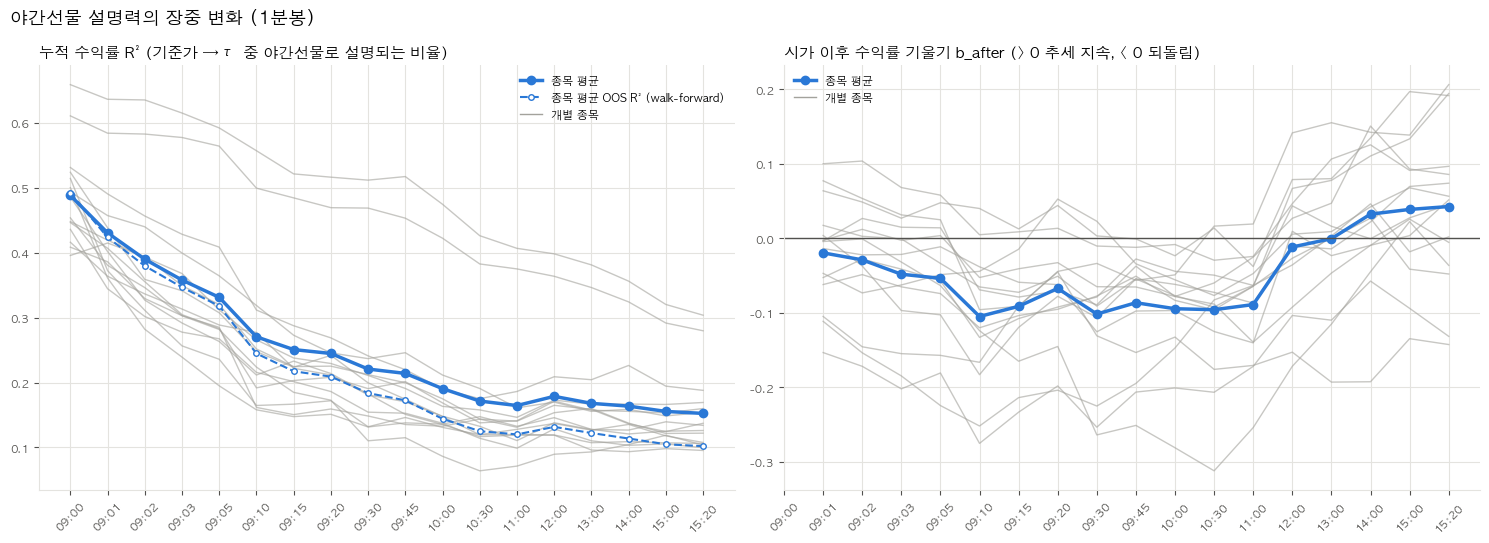

In [15]:
def plot_horizon_curves(results, by_horizon):
    """(1) R²_cum(τ)  (2) b_after(τ) : 종목별 얇은 선 + 종목 평균 굵은 선"""
    x = np.arange(len(HORIZONS))
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

    panels = [
        (axes[0], "R²_cum", "평균 R²_cum",
         "누적 수익률 R² (기준가 → τ 중 야간선물로 설명되는 비율)"),
        (axes[1], "b_after", "평균 b_after",
         "시가 이후 수익률 기울기 b_after (> 0 추세 지속, < 0 되돌림)"),
    ]

    for ax, col, mean_col, title in panels:
        for _, g in results.groupby("code"):
            g = g.set_index("tau").reindex(HORIZONS)
            ax.plot(x, g[col], color=COLOR_MUTED, lw=1, alpha=0.6)

        mean = by_horizon[mean_col].reindex(HORIZONS)
        ax.plot(x, mean, color=COLOR_MAIN, lw=2.5, marker="o", ms=6, label="종목 평균")

        oos_col = {"R²_cum": "평균 OOS R²", "b_after": None}[col]
        if oos_col:
            ax.plot(x, by_horizon[oos_col].reindex(HORIZONS), color=COLOR_MAIN, lw=1.5,
                    ls="--", marker="o", ms=4, mfc="white", label="종목 평균 OOS R² (walk-forward)")
        ax.plot([], [], color=COLOR_MUTED, lw=1, label="개별 종목")

        if col == "b_after":
            ax.axhline(0, color=TEXT_SECONDARY, lw=1)

        ax.set_xticks(x, HORIZONS, rotation=45)
        _style(ax, title)
        ax.legend(fontsize=8, frameon=False)

    fig.suptitle("야간선물 설명력의 장중 변화 (1분봉)", fontsize=13, x=0.01, ha="left")
    fig.tight_layout()

    return fig


fig_curves = plot_horizon_curves(results, by_horizon)
plt.show()

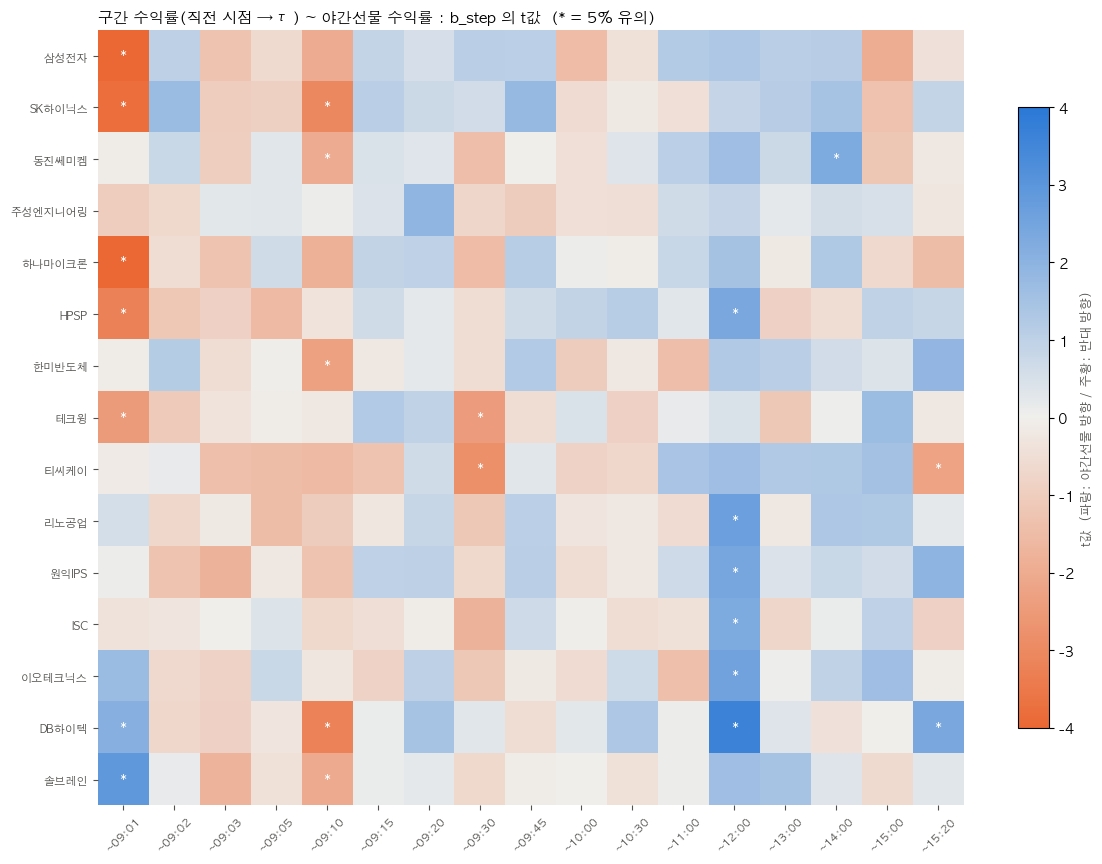

In [16]:
def plot_step_heatmap(results, by_stock):
    """종목 × 구간 : b_step 의 t값 (|t| ≥ 1.96 이면 *)"""
    table = (
        results.pivot(index="code", columns="tau", values="t_step")
        .reindex(index=by_stock.index, columns=HORIZONS[1:])
    )
    interval_labels = [f"~{tau}" for tau in table.columns]

    cmap = LinearSegmentedColormap.from_list(
        "diverging", ["#eb6834", "#f0efec", COLOR_MAIN]
    )

    fig, ax = plt.subplots(figsize=(12, 0.45 * len(table) + 2))
    image = ax.imshow(table.to_numpy(dtype=float), cmap=cmap, vmin=-4, vmax=4, aspect="auto")

    for (r, c), t in np.ndenumerate(table.to_numpy(dtype=float)):
        if np.isfinite(t) and abs(t) >= 1.96:
            ax.text(c, r, "*", ha="center", va="center", fontsize=11, color="white")

    ax.set_xticks(np.arange(len(table.columns)), interval_labels, rotation=45)
    ax.set_yticks(np.arange(len(table)), [STOCKS[c][0] for c in table.index])
    ax.tick_params(colors=TEXT_SECONDARY, labelsize=8)
    for spine in ax.spines.values():
        spine.set_visible(False)

    colorbar = fig.colorbar(image, ax=ax, shrink=0.8)
    colorbar.set_label("t값  (파랑: 야간선물 방향 / 주황: 반대 방향)", color=TEXT_SECONDARY, fontsize=9)

    ax.set_title("구간 수익률(직전 시점 → τ) ~ 야간선물 수익률 : b_step 의 t값  (* = 5% 유의)",
                 loc="left", fontsize=11)
    fig.tight_layout()

    return fig


fig_heatmap = plot_step_heatmap(results, by_stock)
plt.show()

## 7. 결과 저장

In [17]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
tag = "intraday_1m_creon"

results.to_csv(OUTPUT_DIR / f"night_futures_{tag}_results.csv", index=False, encoding="utf-8-sig")
by_stock.to_csv(OUTPUT_DIR / f"night_futures_{tag}_by_stock.csv", encoding="utf-8-sig")
by_horizon.to_csv(OUTPUT_DIR / f"night_futures_{tag}_by_horizon.csv", encoding="utf-8-sig")

for key, fig in {"curves": fig_curves, "step_heatmap": fig_heatmap}.items():
    fig.savefig(OUTPUT_DIR / f"night_futures_{tag}_{key}.png", dpi=150)

print("결과 저장:", OUTPUT_DIR)

결과 저장: /Users/minseok_geum/Desktop/SKKUFI/FDS/본프로젝트/ai_campus_main_proj/backtest/outputs


## 8. 기존 키움 분봉 결과와 비교

- **재현 확인**: 크레온 패널을 기존 표본(키움 13종목, 2025-10-01~2026-10-28)으로 잘라 다시 돌린 결과가 기존 결과와 같아야 한다.
- **표본 확대 효과**: 같은 지표를 기존 표본과 전체 표본으로 나란히 본다.

In [18]:
old_results = pd.read_csv(OUTPUT_DIR / "night_futures_intraday_1m_results.csv", dtype={"code": str})
old_by_horizon = pd.read_csv(OUTPUT_DIR / "night_futures_intraday_1m_by_horizon.csv", index_col="tau")

same_sample = panel[
    panel["code"].isin(old_results["code"].unique())
    & panel["date"].between("2025-10-01", "2026-10-28")
].copy()
same_sample["tau"] = same_sample["tau"].cat.remove_unused_categories()

reproduced = regress_by_horizon(same_sample)
reproduced["tau"] = reproduced["tau"].astype(str)

check = old_results.merge(reproduced, on=["code", "tau"], suffixes=("_old", "_new"))

print(f"비교 행 {len(check)} / 기존 {len(old_results)}")
print("표본 수 다른 행:", int((check["n_old"] != check["n_new"]).sum()))

for column in ["R²_cum", "b_cum", "OOS R²_cum", "b_after", "OOS R²_after", "b_step"]:
    print(f"{column} 최대 차이: {(check[column + '_old'] - check[column + '_new']).abs().max():.6f}")

comparison = pd.DataFrame({
    "R²_cum 기존": old_by_horizon["평균 R²_cum"],
    "R²_cum 전체": by_horizon["평균 R²_cum"].astype(float).set_axis(by_horizon.index.astype(str)),
    "OOS R² 기존": old_by_horizon["평균 OOS R²"],
    "OOS R² 전체": by_horizon["평균 OOS R²"].astype(float).set_axis(by_horizon.index.astype(str)),
    "OOS_after 기존": old_by_horizon["평균 OOS R²_after"],
    "OOS_after 전체": by_horizon["평균 OOS R²_after"].astype(float).set_axis(by_horizon.index.astype(str)),
    "b_after 기존": old_by_horizon["평균 b_after"],
    "b_after 전체": by_horizon["평균 b_after"].astype(float).set_axis(by_horizon.index.astype(str)),
})

print(f"\n기존: {old_results['code'].nunique()}종목 / 전체: {panel['code'].nunique()}종목, {panel['date'].nunique()}거래일")
display(comparison.round(3))

비교 행 234 / 기존 234
표본 수 다른 행: 0
R²_cum 최대 차이: 0.000000
b_cum 최대 차이: 0.000000
OOS R²_cum 최대 차이: 0.000000
b_after 최대 차이: 0.000000
OOS R²_after 최대 차이: 0.000000
b_step 최대 차이: 0.000000

기존: 13종목 / 전체: 15종목, 336거래일


,R²_cum 기존,R²_cum 전체,OOS R² 기존,OOS R² 전체,OOS_after 기존,OOS_after 전체,b_after 기존,b_after 전체
tau,,,,,,,,
09:00,0.521,0.488,0.515,0.492,NaN,NaN,NaN,NaN
09:01,0.457,0.430,0.446,0.424,-0.006,-0.006,-0.023,-0.020
09:02,0.417,0.390,0.400,0.380,-0.027,-0.025,-0.030,-0.029
09:03,0.383,0.358,0.365,0.347,-0.028,-0.025,-0.048,-0.048
09:05,0.357,0.331,0.338,0.318,-0.028,-0.025,-0.052,-0.054
09:10,0.291,0.270,0.263,0.245,-0.027,-0.029,-0.109,-0.105
09:15,0.271,0.251,0.238,0.217,-0.036,-0.035,-0.095,-0.091
09:20,0.263,0.245,0.230,0.209,-0.040,-0.040,-0.069,-0.067
09:30,0.237,0.221,0.201,0.184,-0.038,-0.038,-0.107,-0.102
